In [8]:
from experiment import Experiment

In [17]:
experiment = Experiment(f'swe_base', 'last')
x = experiment.run_full_test('test', 'sd', overlap=1)

test:   0%|          | 0/984 [00:00<?, ?batch/s]

In [ ]:
experiment = Experiment(f'swe_linear', 'last')
experiment.run_full_test('test', 'sd', overlap=1)

In [9]:
experiment = Experiment(f'swe_net_v2', 'e003')
x = experiment.run_full_test('test', 'sd', overlap=1)

test:   0%|          | 0/535 [00:00<?, ?batch/s]

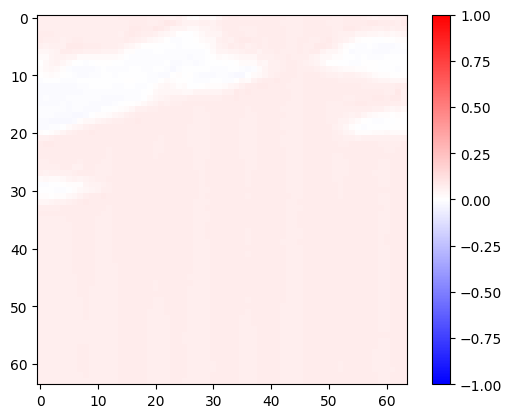

tensor([0.0633, 0.0619, 0.0615, 0.0623, 0.0634, 0.0619, 0.0617, 0.0619, 0.0634,
        0.0618, 0.0615, 0.0621, 0.0633, 0.0619, 0.0615, 0.0622, 0.0632, 0.0620,
        0.0617, 0.0624, 0.0632, 0.0619, 0.0618, 0.0625, 0.0636, 0.0621, 0.0618,
        0.0626, 0.0635, 0.0621, 0.0621, 0.0625])

In [31]:
from matplotlib import pyplot as plt
plt.imshow(x[4, 0, :, :], cmap='bwr', interpolation='none', origin='upper', vmin=-1, vmax=1)
plt.colorbar()
plt.show()

x[0, :, 32, 0]

In [10]:
from matplotlib import pyplot as plt
import xarray as xr
import numpy as np
import os

path1 = '../experiments/swe_base/result'
path2 = '../experiments/swe_net_v2/result'
#ds1 = xr.open_dataset(f'{path1}/202412.nc', engine='h5netcdf')
#ds2 = xr.open_dataset(f'{path2}/202412_o1.nc', engine='h5netcdf')
#ds3 = xr.open_dataset(f'{path2}/202412_o2.nc', engine='h5netcdf')
ds2 = xr.open_dataset(f'{path2}/202412.nc', engine='h5netcdf')
ds2.output.mean()

<xarray.DataArray 'output' ()> Size: 4B
array(-0.00092715, dtype=float32)

In [15]:
ds2.output.min()

<xarray.DataArray 'output' ()> Size: 4B
array(-0.03307754, dtype=float32)

In [12]:
def draw_images(ds, rng, file, title):
    output_plot = np.mean(ds.output.values[rng], axis=0)
    target_plot = np.mean(ds.target.values[rng], axis=0)
    clim_mean = np.mean(ds.clim.values, axis=0)
    output_plot[clim_mean == 0] = np.nan
    target_plot[clim_mean == 0] = np.nan
    output_plot[clim_mean > 5] = 0
    target_plot[clim_mean > 5] = 0

    plt.figure(figsize=(12, 8))

    plt.subplot(2, 1, 1)
    plt.contourf(output_plot, levels=np.linspace(-0.2, 0.2, 21), extend='both', cmap='bwr')
    plt.colorbar()
    plt.title(title)

    plt.subplot(2, 1, 2)
    plt.contourf(target_plot, levels=np.linspace(-1, 1, 21), extend='both', cmap='bwr')
    plt.colorbar()

    plt.tight_layout()
    plt.savefig(f'../images/swe_net_comp/{file}.png', dpi=150, bbox_inches='tight')
    plt.close()

def draw_ds(ds, file, title):
    draw_images(ds, slice(0, 7), file + "_1", title + ", Неделя 1")
    draw_images(ds, slice(0, 14), file + "_2", title + ", Неделя 2")
    draw_images(ds, slice(0, 30), file + "_3", title + ", Месяц 1")
    draw_images(ds, slice(30, 60), file + "_4", title + ", Месяц 2")
    draw_images(ds, slice(60, 90), file + "_5", title + ", Месяц 3")
    draw_images(ds, slice(90, None), file + "_6", title + ", Месяц 4")

#draw_ds(ds1, 'base', 'Прогноз ИВМ, декабрь 2024')
draw_ds(ds2, 'corr', 'Коррекция, декабрь 2024')
#draw_ds(ds3, 'overlap', 'Коррекция с перекрытием, декабрь 2024')
#draw_ds(ds4, 'corr14', 'Коррекция 14 эпоха, декабрь 2024')

In [12]:
all_mse, all_mse_log = [], []

lat_min, lat_max = 45, 70
lon_min, lon_max = 30, 60
for i, file in enumerate(os.listdir(path)):
    print(file)
    ds = xr.open_dataset(f'{path}/{file}', engine='h5netcdf')
    lat_mask = (ds.lat >= lat_min) & (ds.lat <= lat_max)
    lon_mask = (ds.lon >= lon_min) & (ds.lon <= lon_max)
    
    output_etr = ds.output.values[:, lat_mask, :][:, :, lon_mask]
    target_etr = ds.target.values[:, lat_mask, :][:, :, lon_mask]
    clim_etr = ds.clim.values[:, lat_mask, :][:, :, lon_mask]

    mask = ~(np.isnan(output_etr) | np.isnan(target_etr)) & (clim_etr > 0) & (clim_etr < 5)

    n_days = output_etr.shape[0]
    n_months = n_days // 30
    for m in range(n_months):
        start = m * 30
        end = start + 30
        
        output_month = np.nanmean(output_etr[start:end], axis=0)
        target_month = np.nanmean(target_etr[start:end], axis=0)
        clim_month = np.nanmean(clim_etr[start:end], axis=0)
        mask_month = np.nanmean(mask[start:end]).any(axis=0)
        
        if mask_month.any():
            mse_log = np.mean((output_month[mask_month] - target_month[mask_month]) ** 2)
            all_mse_log.append(mse_log)
            
            x = np.exp(output_month[mask_month] + clim_month[mask_month]) - 1
            y = np.exp(target_month[mask_month] + clim_month[mask_month]) - 1
            mse = np.mean((x - y) ** 2)
            all_mse.append(mse)
        break

all_mse, all_mse_log = np.array(all_mse), np.array(all_mse_log)
total_mse, total_mse_log = np.mean(all_mse), np.mean(all_mse_log)
print(f"RMSE log in ETR: {np.sqrt(total_mse_log):.6f}")
print(np.round(np.sqrt(all_mse_log), 4))

print(f"RMSE in ETR: {np.sqrt(total_mse):.6f}")
print(np.round(np.sqrt(all_mse), 2))

202409.nc
202410.nc
202411.nc
202412.nc
202501.nc
202502.nc
202503.nc
202504.nc
202505.nc
202506.nc
202507.nc
202508.nc
202509.nc
202510.nc
202511.nc
202512.nc
202601.nc
202602.nc
202603.nc
202604.nc
202605.nc
RMSE log in ETR: 0.451713
[0.5732 0.4677 0.3445 0.3585 0.317  0.3749 0.5842 0.6948 0.3568 0.0463
 0.088  0.2521 0.5834 0.6183 0.3567 0.3415 0.4006 0.3696 0.5561 0.7037
 0.3955]
RMSE in ETR: 97.826492
[1.0211e+02 8.7890e+01 4.3060e+01 3.6940e+01 3.3460e+01 3.2030e+01
 4.1660e+01 5.1570e+01 1.9689e+02 8.0500e+00 1.8000e-01 2.2270e+01
 1.2209e+02 7.1010e+01 2.8290e+01 4.0610e+01 4.1390e+01 4.4790e+01
 4.8300e+01 6.2730e+01 3.1836e+02]


In [6]:
all_mse, all_mse_log = [], []

lat_min, lat_max = 45, 70
lon_min, lon_max = 30, 60
for i, file in enumerate(os.listdir(path)):
    print(file)
    ds = xr.open_dataset(f'{path}/{file}', engine='h5netcdf')
    lat_mask = (ds.lat >= lat_min) & (ds.lat <= lat_max)
    lon_mask = (ds.lon >= lon_min) & (ds.lon <= lon_max)

    output_etr = ds.output.values[:, lat_mask, :][:, :, lon_mask] * 0
    target_etr = ds.target.values[:, lat_mask, :][:, :, lon_mask]
    clim_etr = ds.clim.values[:, lat_mask, :][:, :, lon_mask]

    mask = ~(np.isnan(output_etr) | np.isnan(target_etr)) & (clim_etr > 0) & (clim_etr < 5)

    n_days = output_etr.shape[0]
    n_months = n_days // 30
    for m in range(n_months):
        start = m * 30
        end = start + 30
        
        output_month = np.nanmean(output_etr[start:end], axis=0)
        target_month = np.nanmean(target_etr[start:end], axis=0)
        clim_month = np.nanmean(clim_etr[start:end], axis=0)
        mask_month = np.nanmean(mask[start:end]).any(axis=0)
        
        if mask_month.any():
            mse_log = np.mean((output_month[mask_month] - target_month[mask_month]) ** 2)
            all_mse_log.append(mse_log)
            
            x = np.exp(output_month[mask_month] + clim_month[mask_month]) - 1
            y = np.exp(target_month[mask_month] + clim_month[mask_month]) - 1
            mse = np.mean((x - y) ** 2)
            all_mse.append(mse)
        break

all_mse, all_mse_log = np.array(all_mse), np.array(all_mse_log)
total_mse, total_mse_log = np.mean(all_mse), np.mean(all_mse_log)
print(f"RMSE log in ETR: {np.sqrt(total_mse_log):.6f}")
print(np.round(np.sqrt(all_mse_log), 4))

print(f"RMSE in ETR: {np.sqrt(total_mse):.6f}")
print(np.round(np.sqrt(all_mse), 2))

202409.nc
202410.nc
202411.nc
202412.nc
202501.nc
202502.nc
202503.nc
202504.nc
202505.nc
202506.nc
202507.nc
202508.nc
202509.nc
202510.nc
202511.nc
202512.nc
202601.nc
202602.nc
202603.nc
202604.nc
202605.nc
RMSE log in ETR: 0.439292
[0.5091 0.4038 0.3498 0.3803 0.3146 0.3801 0.5747 0.7133 0.3522 0.0461
 0.0787 0.2831 0.5474 0.634  0.3534 0.3511 0.4139 0.3716 0.5652 0.6093
 0.344 ]
RMSE in ETR: 20.516937
[ 6.87 14.44 14.65 18.9  23.6  25.69 29.88 32.63  7.26  0.12  0.12  1.01
  4.61 14.92 16.27 20.87 24.75 23.9  40.46 31.46  5.37]
